# Stochastic processes: laws, boundaries, and dynamics

This family-13 notebook uses generated inputs to inspect exact transition laws,
continuous generators, mean reversion, positive-state boundaries, and jumps.
Heston uses QuantLib QE; a custom Itô equation uses sdeint SRI2. Their numerical
outputs are labeled as approximations. Install `convexity[notebooks,processes]`.
Time is measured in a common arbitrary unit throughout; parameters are supplied,
not estimated. No pricing measure or market data is assumed.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "convexity").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from convexity.math import processes as p

rng = np.random.default_rng(1300)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
print("Python:", sys.executable)

Python: /home/ethan/miniconda3/envs/quant/bin/python


## Conditional laws and mean reversion

An OU transition shifts toward its long-run mean and approaches a limiting
variance. Its exact finite-time Gaussian law supplies both moments and quantiles.
A path is sampled sequentially from those conditional laws, so time points remain
dependent. The plots retain the supplied initial level.

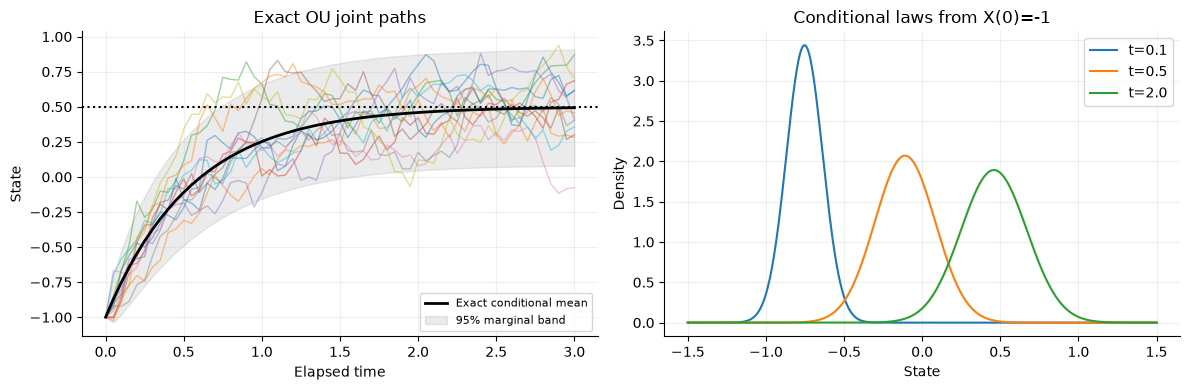

In [2]:
ou = p.OrnsteinUhlenbeck(1.8, .5, .4)
times = np.linspace(0, 3, 61)
paths = ou.sample(-1., times, draws=12, rng=rng)
means = np.array([ou.transition(-1., t).mean() for t in times])
variances = np.array([ou.transition(-1., t).covariance() for t in times])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(times, paths.values.T, alpha=.45, lw=1)
axes[0].plot(times, means, color="black", lw=2, label="Exact conditional mean")
axes[0].fill_between(times, means-1.96*np.sqrt(variances), means+1.96*np.sqrt(variances),
                     color="black", alpha=.08, label="95% marginal band")
axes[0].axhline(.5, ls=":", color="black")
axes[0].set(xlabel="Elapsed time", ylabel="State", title="Exact OU joint paths")
axes[0].legend(fontsize=8)
x = np.linspace(-1.5, 1.5, 500)
for t in [.1, .5, 2.]:
    axes[1].plot(x, ou.transition(-1., t).distribution().density(x), label=f"t={t}")
axes[1].set(xlabel="State", ylabel="Density", title="Conditional laws from X(0)=-1")
axes[1].legend()
plt.tight_layout()
plt.show()

## Coupled vector dynamics

Off-diagonal reversion and a shared loading both affect the covariance geometry.
The stationary covariance solves a continuous Lyapunov equation. Exact matrix
exponentials also work with singular drift matrices, such as integrated Brownian
motion, without pretending those nonstationary systems have a stationary law.

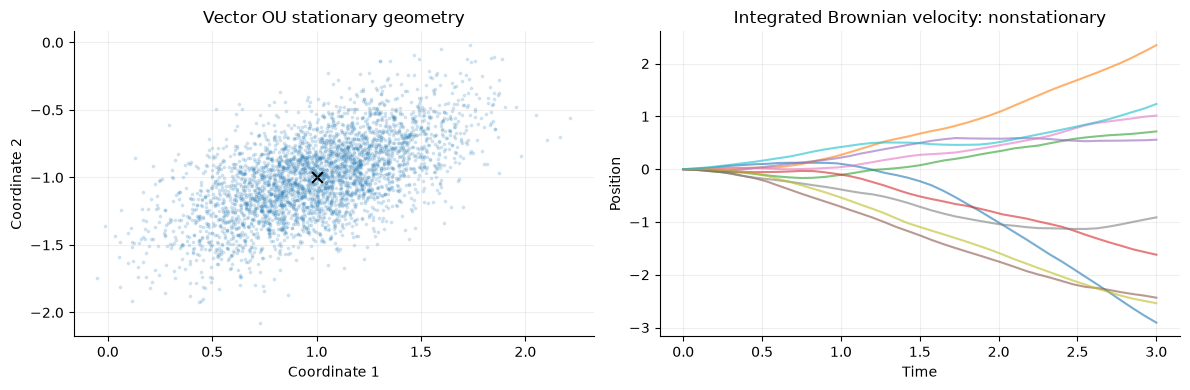

,x1,x2
x1,0.115431,0.061495
x2,0.061495,0.090876


In [3]:
vector = p.VectorOrnsteinUhlenbeck([[1.5, -.6], [.2, .8]], [1., -1.], [[.5, .15], [.1, .4]])
stationary = vector.stationary()
cloud = stationary.sample(3500, rng=rng)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(cloud[:, 0], cloud[:, 1], s=3, alpha=.15)
axes[0].scatter(*stationary.mean(), color="black", marker="x", s=60)
axes[0].set(xlabel="Coordinate 1", ylabel="Coordinate 2", title="Vector OU stationary geometry")
integrated = p.LinearDiffusion([[0., 1.], [0., 0.]], [[0.], [.5]])
flight = integrated.sample([0., 0.], np.linspace(0, 3, 41), draws=10, rng=rng)
axes[1].plot(flight.times, flight.values[:, :, 0].T, alpha=.6)
axes[1].set(xlabel="Time", ylabel="Position", title="Integrated Brownian velocity: nonstationary")
plt.tight_layout()
plt.show()
pd.DataFrame(stationary.covariance(), columns=["x1", "x2"], index=["x1", "x2"])

## CIR at an attainable boundary

Both parameter sets have positive long-run variance. The Feller condition governs
boundary attainability, not whether the model may be constructed. Exact scaled
noncentral chi-square sampling remains nonnegative in both regimes, even when
started from zero. A histogram near zero reveals how sharply these laws differ.

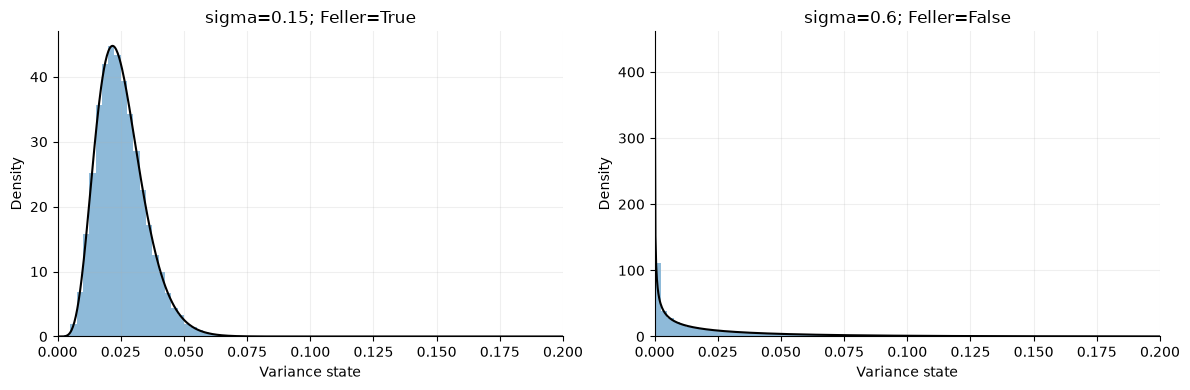

,sigma,Feller,exact mean,sample mean,exact variance,sample variance
0,0.15,True,0.025285,0.025276,0.000090,0.000090
1,0.60,False,0.025285,0.025245,0.001438,0.001412


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rows = []
for ax, sigma in zip(axes, [.15, .6]):
    cir = p.CIR(2., .04, sigma)
    kernel = cir.transition(0., .5)
    sample = kernel.sample(40000, rng=rng)
    ax.hist(sample, bins=np.linspace(0, .2, 81), density=True, alpha=.5)
    grid = np.linspace(.00005, .2, 700)
    ax.plot(grid, kernel.distribution().density(grid), color="black", lw=1.5)
    ax.set(xlabel="Variance state", ylabel="Density", xlim=(0, .2),
           title=f"sigma={sigma}; Feller={cir.feller_satisfied}")
    rows.append({"sigma": sigma, "Feller": cir.feller_satisfied,
                 "exact mean": float(kernel.mean()), "sample mean": sample.mean(),
                 "exact variance": float(kernel.covariance()), "sample variance": sample.var()})
plt.tight_layout()
plt.show()
pd.DataFrame(rows)

## Jump compensation and asymmetric tails

GBM and Merton below share the same total expected proportional drift. Merton's
continuous drift includes the explicit jump compensator, so negative mean jumps
do not inadvertently change that total drift. Equal expected levels do not imply
equal distributions. The Merton histogram is generated by exact Poisson-count
sampling; it is not an asserted continuous density.

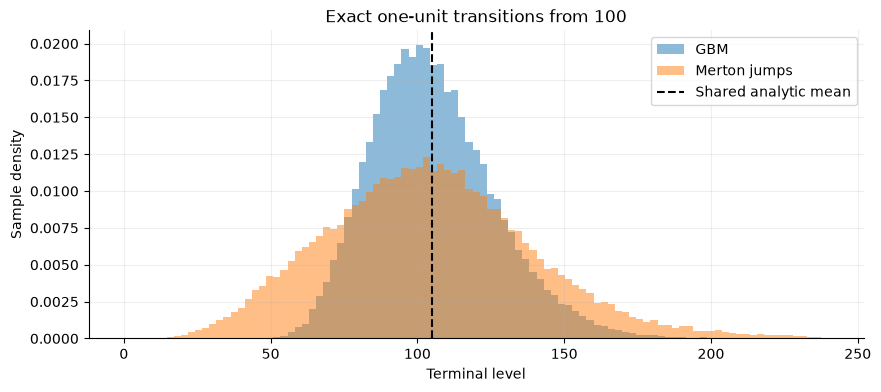

,model,analytic mean,sample mean,5% quantile,95% quantile
0,GBM,105.12711,105.352701,74.274814,143.217926
1,Merton,105.12711,104.971299,49.434061,167.049123


In [5]:
gbm = p.GeometricBrownianMotion(.05, .2).transition(100., 1.)
merton = p.MertonJumpDiffusion(.05, .2, 1.2, -.15, .25).transition(100., 1.)
g = gbm.sample(50000, rng=rng)
j = merton.sample(50000, rng=rng)
fig, ax = plt.subplots()
bins = np.linspace(0, 240, 100)
ax.hist(g, bins=bins, density=True, alpha=.5, label="GBM")
ax.hist(j, bins=bins, density=True, alpha=.5, label="Merton jumps")
ax.axvline(float(merton.mean()), color="black", ls="--", label="Shared analytic mean")
ax.set(xlabel="Terminal level", ylabel="Sample density", title="Exact one-unit transitions from 100")
ax.legend()
plt.show()
pd.DataFrame({"model": ["GBM", "Merton"],
              "analytic mean": [float(gbm.mean()), float(merton.mean())],
              "sample mean": [g.mean(), j.mean()],
              "5% quantile": [np.quantile(g,.05), np.quantile(j,.05)],
              "95% quantile": [np.quantile(g,.95), np.quantile(j,.95)]})

## Heston: coupled spot and variance

QE is a numerical joint transition. It preserves nonnegative variance but is not
advertised as an exact Heston law. The level-coordinate loading includes the
spot/variance cross covariance. Refining `substeps` changes the numerical scheme;
it does not turn independent marginals into a joint law.

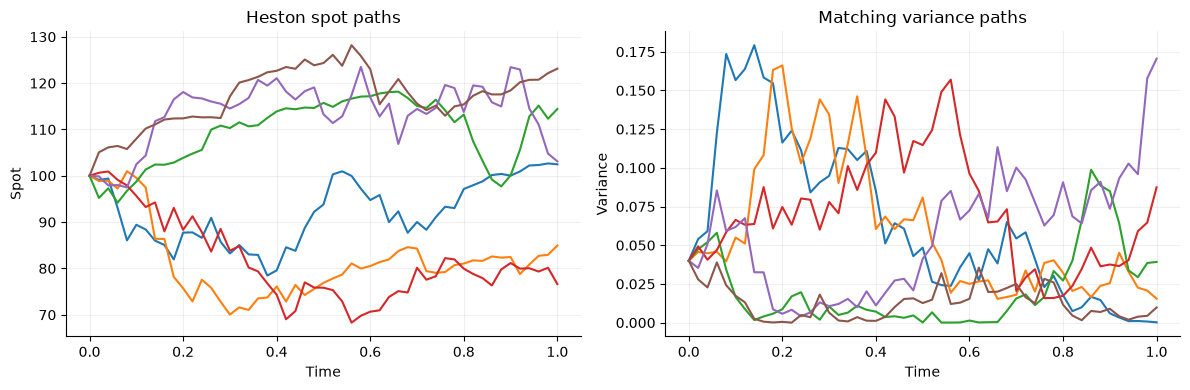

{'method': 'qe', 'backend': 'QuantLib', 'exact': False}


In [6]:
heston = p.Heston(.05, 2., .04, .5, -.7)
hp = heston.sample([100., .04], np.linspace(0, 1, 51), draws=6, rng=rng, substeps=4)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i in range(len(hp.values)):
    axes[0].plot(hp.times, hp.values[i,:,0], label=f"Path {i+1}")
    axes[1].plot(hp.times, hp.values[i,:,1])
axes[0].set(xlabel="Time", ylabel="Spot", title="Heston spot paths")
axes[1].set(xlabel="Time", ylabel="Variance", title="Matching variance paths")
plt.tight_layout()
plt.show()
print({"method": hp.method, "backend": hp.backend, "exact": hp.exact})

## Custom Itô dynamics and the deterministic limit

User callbacks receive `(time,state)` and return drift plus a loading, with no
registration step. The deterministic limit makes discretization error visible
without Monte Carlo noise. For a stochastic equation, strong convergence must
instead compare approximations driven by the same Brownian increments; that
check lives in the test suite.

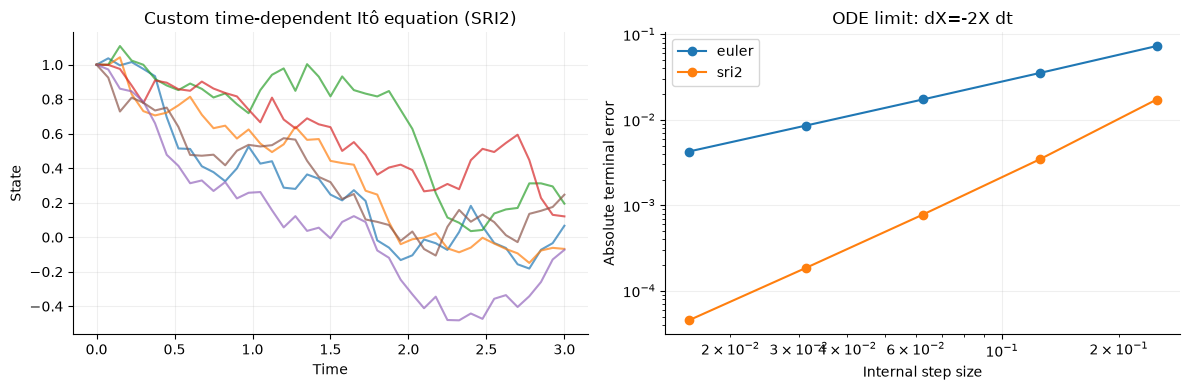

In [7]:
custom = p.ItoDiffusion(lambda t,x: -.8*x+.1*np.sin(t), lambda t,x: [.3])
cp = custom.sample(1., np.linspace(0, 3, 41), draws=6, rng=rng, method="sri2", substeps=4)
deterministic = p.ItoDiffusion(lambda t,x: -2*x, lambda t,x: [0.])
steps = np.array([4, 8, 16, 32, 64])
errors = {}
for method in ["euler", "sri2"]:
    errors[method] = [abs(float(deterministic.transition(1., 1., method=method, substeps=int(n))
                               .sample(rng=np.random.default_rng(3)))-np.exp(-2)) for n in steps]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cp.times, cp.values.T, alpha=.7)
axes[0].set(xlabel="Time", ylabel="State", title="Custom time-dependent Itô equation (SRI2)")
for method, error in errors.items():
    axes[1].loglog(1/steps, error, "o-", label=method)
axes[1].set(xlabel="Internal step size", ylabel="Absolute terminal error", title="ODE limit: dX=-2X dt")
axes[1].legend()
plt.tight_layout()
plt.show()

The examples separate exact transition laws, numerical kernels and empirical
summaries. Brownian/OU/GBM/CIR laws support direct mathematical inspection;
Heston and arbitrary SDEs retain scheme metadata. Rough processes and broader
simulation machinery remain later roadmap families.